In [5]:
import os, sys
REPO = "/Users/alishaperumal/Desktop/AI_Assignment2/AI_Assignment2"
os.chdir(REPO)
sys.path.insert(0, REPO)
print(os.getcwd(), os.path.exists("data.py"), os.path.exists("metrics.py"), sys.executable)

/Users/alishaperumal/Desktop/AI_Assignment2/AI_Assignment2 True True /Users/alishaperumal/Desktop/AI_Assignment2/AI_Assignment2/.venv/bin/python


In [6]:
import os, sys
print(os.getcwd())
print(os.path.exists("data.py"), os.path.exists("metrics.py"))
print(sys.executable)

/Users/alishaperumal/Desktop/AI_Assignment2/AI_Assignment2
True True
/Users/alishaperumal/Desktop/AI_Assignment2/AI_Assignment2/.venv/bin/python


In [7]:
import json, os, collections, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib; matplotlib.use(os.environ.get("MPLBACKEND", matplotlib.get_backend()))
import matplotlib.pyplot as plt
from skimage.segmentation import find_boundaries
import data as D, metrics as M

warnings.filterwarnings("ignore")
Path("figures").mkdir(exist_ok=True); Path("results").mkdir(exist_ok=True)
SUMMARY = {}          # collected facts -> results/eda_summary.json
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("train json:", D.TRAIN_JSON, D.TRAIN_JSON.exists())

train json: data/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json True


In [8]:
coco = D.load_coco()
obs = collections.defaultdict(list)                      # observation -> annotation-set (image entry) ids
for im in coco["images"]:
    obs[D.obs_id_from_name(im["file_name"])].append(im["id"])
SUMMARY["n_image_entries"] = len(coco["images"]); SUMMARY["n_observations"] = len(obs)
SUMMARY["n_annotations"] = len(coco["annotations"])
print(f'{len(coco["images"])} image entries, {len(obs)} unique observations, {len(coco["annotations"])} polygons')
print("example file names:", [im["file_name"] for im in coco["images"][:3]])
print("categories:", coco.get("categories"))

1154 image entries, 707 unique observations, 8199 polygons
example file names: ['20140609195854Bh.jpeg', '20111116063134Lh.jpeg', '20111116063134Lh.jpeg']
categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]


instruments (train observations): {'Lh': 127, 'Ch': 125, 'Mh': 125, 'Bh': 118, 'Th': 110, 'Uh': 102}
date range: 2011-01-09 10:47:34 -> 2022-08-03 07:47:52
per instrument:
                            min                 max  count
instrument                                               
Bh         2011-03-27 14:35:54 2022-07-21 18:53:32    118
Ch         2011-01-09 10:47:34 2021-12-29 12:01:30    125
Lh         2011-01-19 08:26:34 2021-12-31 22:34:30    127
Mh         2011-01-23 17:49:14 2022-07-24 18:53:52    125
Th         2011-02-11 08:41:14 2022-08-03 07:47:52    110
Uh         2011-03-01 08:26:54 2022-04-18 02:09:50    102


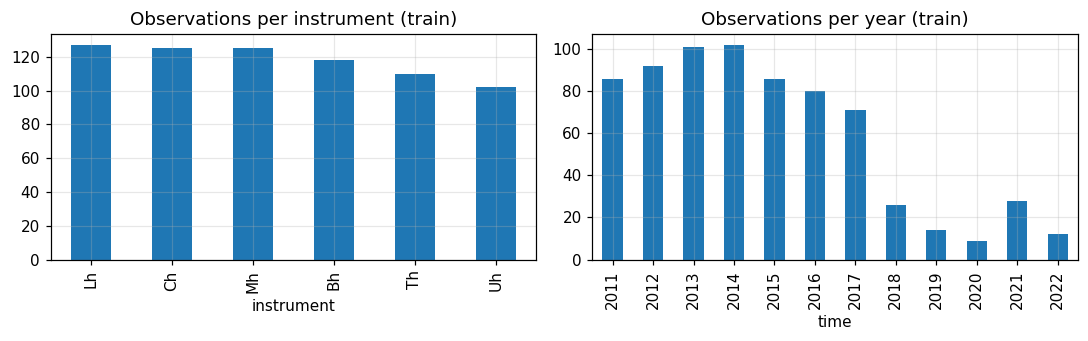

In [9]:
if not (D.CACHE_DIR / "catalog.csv").exists():
    D.build_cache()                                       # decodes polygons once, ~minutes on the full set
cat = D.load_catalog()
inst_counts = cat.drop_duplicates("obs")["instrument"].value_counts()
years = cat.drop_duplicates("obs")["time"].dt.year.value_counts().sort_index()
print("instruments (train observations):", inst_counts.to_dict())
print("date range:", cat.time.min(), "->", cat.time.max())
print("per instrument:\n", cat.drop_duplicates("obs").groupby("instrument")["time"].agg(["min","max","count"]))
SUMMARY["instruments_train"] = inst_counts.to_dict(); SUMMARY["years_train"] = {int(k): int(v) for k, v in years.items()}
SUMMARY["date_range_train"] = [str(cat.time.min()), str(cat.time.max())]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
inst_counts.plot.bar(ax=ax[0], title="Observations per instrument (train)"); years.plot.bar(ax=ax[1], title="Observations per year (train)")
plt.tight_layout(); plt.savefig("figures/eda_instruments_years.png"); plt.show()

In [10]:
per_obs = cat.groupby("obs")["set_id"].count()
print("annotation sets per observation:", per_obs.value_counts().sort_index().to_dict())
print("share of observations with >=2 annotation sets:", round(float((per_obs >= 2).mean()), 3))
SUMMARY["sets_per_observation"] = {int(k): int(v) for k, v in per_obs.value_counts().sort_index().items()}
# The json has no annotator id here, so 'do all annotators label all observations' is judged from the count
# distribution: if every observation had the same number of sets the answer is yes.
print("all observations have the same number of sets:", per_obs.nunique() == 1)

annotation sets per observation: {1: 411, 2: 145, 3: 151}
share of observations with >=2 annotation sets: 0.419
all observations have the same number of sets: False


count    1154.00
mean        7.10
std         4.38
min         1.00
25%         4.00
50%         7.00
75%        10.00
max        26.00
Name: n_inst, dtype: float64
annotation sets with NO filament: 0 (0.0%)
observations where annotators disagree on 'empty' vs 'not empty': 0


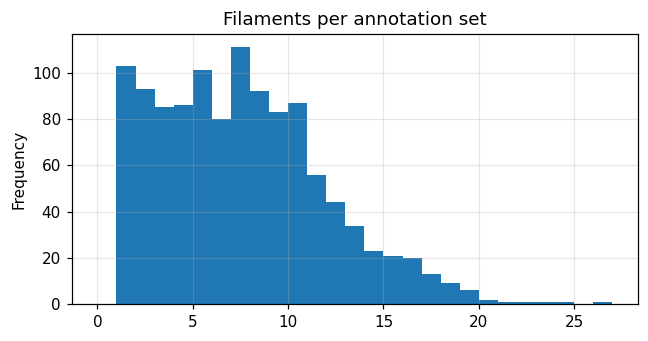

In [11]:
print(cat["n_inst"].describe().round(2))
empty = (cat["n_inst"] == 0)
print(f"annotation sets with NO filament: {int(empty.sum())} ({empty.mean():.1%})")
SUMMARY["filaments_per_set"] = cat["n_inst"].describe().round(3).to_dict(); SUMMARY["empty_sets"] = int(empty.sum())
by_obs_empty = cat.groupby("obs")["n_inst"].apply(lambda s: (s == 0).any() and not (s == 0).all())
print("observations where annotators disagree on 'empty' vs 'not empty':", int(by_obs_empty.sum()))
fig, ax = plt.subplots(figsize=(6, 3.2)); cat["n_inst"].plot.hist(bins=range(0, int(cat.n_inst.max()) + 2), ax=ax, title="Filaments per annotation set")
plt.tight_layout(); plt.savefig("figures/eda_filaments_per_image.png"); plt.show()

mean foreground fraction: 0.00359 (0.359%);  median 0.00302;  max 0.0167
background:foreground pixel ratio = 278:1  (suggested BCE pos_weight ~ sqrt = 17)
instance areas (px): min 9 median of mean 1866 max 37739


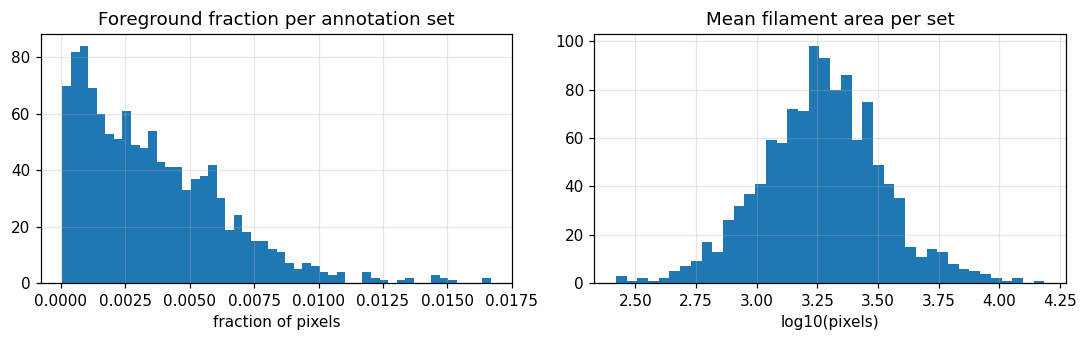

In [12]:
fg = cat["fg_frac"]
print(f"mean foreground fraction: {fg.mean():.5f} ({fg.mean():.3%});  median {fg.median():.5f};  max {fg.max():.4f}")
pos_weight = (1 - fg.mean()) / fg.mean()
print(f"background:foreground pixel ratio = {pos_weight:.0f}:1  (suggested BCE pos_weight ~ sqrt = {np.sqrt(pos_weight):.0f})")
a = cat.loc[cat.n_inst > 0, "mean_area"]
print("instance areas (px): min", int(cat.loc[cat.n_inst>0,"min_area"].min()), "median of mean", int(a.median()), "max", int(cat.max_area.max()))
SUMMARY.update(fg_frac_mean=float(fg.mean()), fg_frac_median=float(fg.median()), bg_fg_ratio=float(pos_weight))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(fg, bins=50); ax[0].set(title="Foreground fraction per annotation set", xlabel="fraction of pixels")
ax[1].hist(np.log10(cat.loc[cat.n_inst > 0, "mean_area"]), bins=40); ax[1].set(title="Mean filament area per set", xlabel="log10(pixels)")
plt.tight_layout(); plt.savefig("figures/eda_imbalance.png"); plt.show()

test images: 180
            train   test
instrument              
Bh          0.167  0.183
Ch          0.177  0.183
Lh          0.180  0.189
Mh          0.177  0.144
Th          0.156  0.150
Uh          0.144  0.150
test date range: 2011-01-20 10:55:34 -> 2022-07-28 18:53:52
train/test time overlap: True


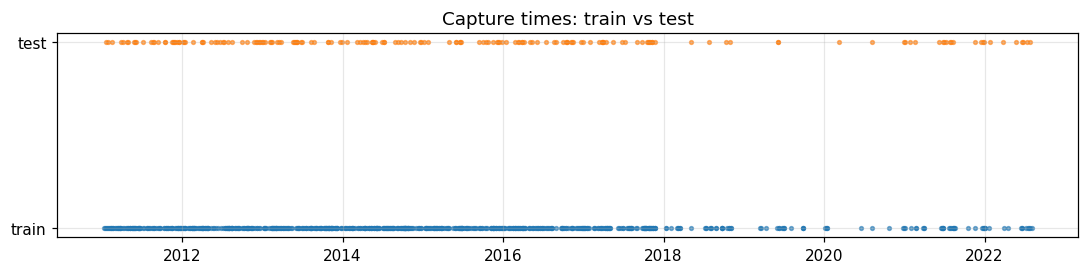

In [13]:
tcat = D.test_catalog()
print("test images:", len(tcat))
tr_mix = cat.drop_duplicates("obs")["instrument"].value_counts(normalize=True)
te_mix = tcat["instrument"].value_counts(normalize=True)
mix = pd.DataFrame({"train": tr_mix, "test": te_mix}).fillna(0).round(3); print(mix)
print("test date range:", tcat.time.min(), "->", tcat.time.max())
print("train/test time overlap:", tcat.time.min() <= cat.time.max() and cat.time.min() <= tcat.time.max())
SUMMARY.update(n_test_images=len(tcat), instrument_mix=mix.to_dict(), date_range_test=[str(tcat.time.min()), str(tcat.time.max())])
fig, ax = plt.subplots(figsize=(10, 2.6))
for name, t in (("train", cat.drop_duplicates("obs")), ("test", tcat)):
    ax.scatter(t["time"], [name] * len(t), s=6, alpha=.6)
ax.set_title("Capture times: train vs test"); plt.tight_layout(); plt.savefig("figures/eda_timeline.png"); plt.show()

In [14]:
n_deg = int((cat.n_degenerate_rings > 0).sum())
print("annotation sets with degenerate rings (<3 points) dropped:", n_deg, " total rings:", int(cat.n_degenerate_rings.clip(lower=0).sum()))
print("sets with EMPTY masks after decoding:", int((cat.n_empty_masks > 0).sum()))
ov = cat[cat.overlap_px > 0]
print(f"sets where instances overlap each other: {len(ov)} ({len(ov)/len(cat):.1%}); total overlapping px {int(cat.overlap_px.clip(lower=0).sum())}")
print(f"sets with tiny instances (<{D.TINY_AREA_PX}px): {int((cat.n_tiny > 0).sum())}; tiny instances: {int(cat.n_tiny.sum())}")
SUMMARY.update(degenerate_sets=n_deg, overlap_sets=int(len(ov)), tiny_instances=int(cat.n_tiny.sum()))
# NOTE: if the cache was reused from an earlier run, overlap/degenerate stats are -1; rebuild with `python data.py build-cache --overwrite`.

annotation sets with degenerate rings (<3 points) dropped: 0  total rings: 0
sets with EMPTY masks after decoding: 0
sets where instances overlap each other: 5 (0.4%); total overlapping px 5041
sets with tiny instances (<20px): 1; tiny instances: 1


         PQ     SQ     RQ  pixel_dice  one_to_many  many_to_one
mean  0.342  0.619  0.536       0.624        0.146        0.146
std   0.147  0.111  0.218       0.123        0.400        0.400
50%   0.341  0.631  0.541       0.641        0.000        0.000


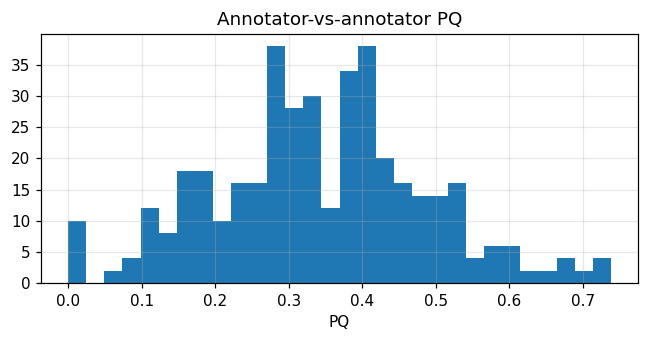

In [15]:
rng = np.random.default_rng(0)
multi = [o for o, g in cat.groupby("obs") if len(g) >= 2]
sample = list(rng.choice(multi, size=min(100, len(multi)), replace=False)) if multi else []
sets_by_obs = {o: [D.load_instance_map(s) for s in cat[cat.obs == o]["set_id"]] for o in sample}
rows = M.annotator_agreement(sets_by_obs)
ag = pd.DataFrame(rows)
if len(ag):
    print(ag[["PQ", "SQ", "RQ", "pixel_dice", "one_to_many", "many_to_one"]].describe().loc[["mean", "std", "50%"]].round(3))
    SUMMARY["annotator_agreement"] = ag[["PQ", "SQ", "RQ", "pixel_dice"]].mean().round(4).to_dict()
    SUMMARY["annotator_agreement_n_pairs"] = int(len(ag))
    fig, ax = plt.subplots(figsize=(6, 3.2)); ax.hist(ag.PQ, bins=30); ax.set(title="Annotator-vs-annotator PQ", xlabel="PQ")
    plt.tight_layout(); plt.savefig("figures/eda_annotator_agreement.png"); plt.show()
else:
    print("no observation has >=2 annotation sets")

{
 "n_obs": 707,
 "n_train": 584,
 "n_val": 122,
 "n_dropped": 1,
 "val_fraction": 0.17256011315417255,
 "instrument_mix_train": {
  "Mh": 0.1832,
  "Lh": 0.1781,
  "Ch": 0.1729,
  "Bh": 0.1627,
  "Th": 0.1592,
  "Uh": 0.1438
 },
 "instrument_mix_val": {
  "Lh": 0.1885,
  "Bh": 0.1885,
  "Ch": 0.1885,
  "Mh": 0.1475,
  "Uh": 0.1475,
  "Th": 0.1393
 },
 "instrument_mix_test": {
  "Lh": 0.1889,
  "Ch": 0.1833,
  "Bh": 0.1833,
  "Uh": 0.15,
  "Th": 0.15,
  "Mh": 0.1444
 },
 "train_span": [
  "2011-01-09 10:47:34",
  "2022-08-03 07:47:52"
 ],
 "val_span": [
  "2011-02-21 17:38:14",
  "2022-07-21 18:53:32"
 ]
}


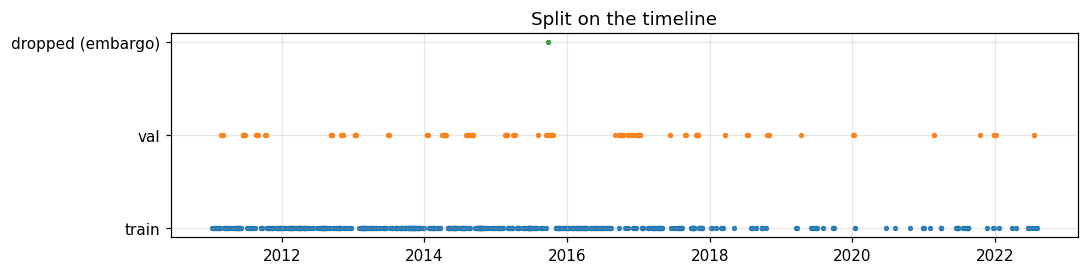

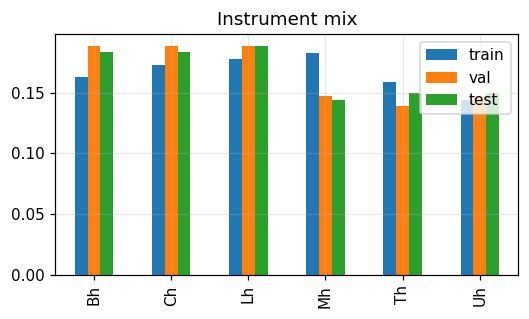

In [16]:
split = D.make_split(cat, tcat, val_frac=0.17, block_days=14.0, gap_days=1.0, seed=42)
D.save_split(split)
print(json.dumps(split["report"], indent=1))
SUMMARY["split"] = split["report"]
t = cat.drop_duplicates("obs").set_index("obs")["time"]
fig, ax = plt.subplots(figsize=(10, 2.6))
for lab, ids in (("train", split["train"]), ("val", split["val"]), ("dropped (embargo)", split["dropped"])):
    ax.scatter(t.loc[ids], [lab] * len(ids), s=6)
ax.set_title("Split on the timeline"); plt.tight_layout(); plt.savefig("figures/eda_split_timeline.png"); plt.show()
mixs = pd.DataFrame({"train": pd.Series(split["report"]["instrument_mix_train"]), "val": pd.Series(split["report"]["instrument_mix_val"]),
                     "test": pd.Series(split["report"]["instrument_mix_test"] or {})}).fillna(0)
mixs.plot.bar(title="Instrument mix", figsize=(5, 3)); plt.tight_layout(); plt.savefig("figures/eda_split_mix.png"); plt.show()

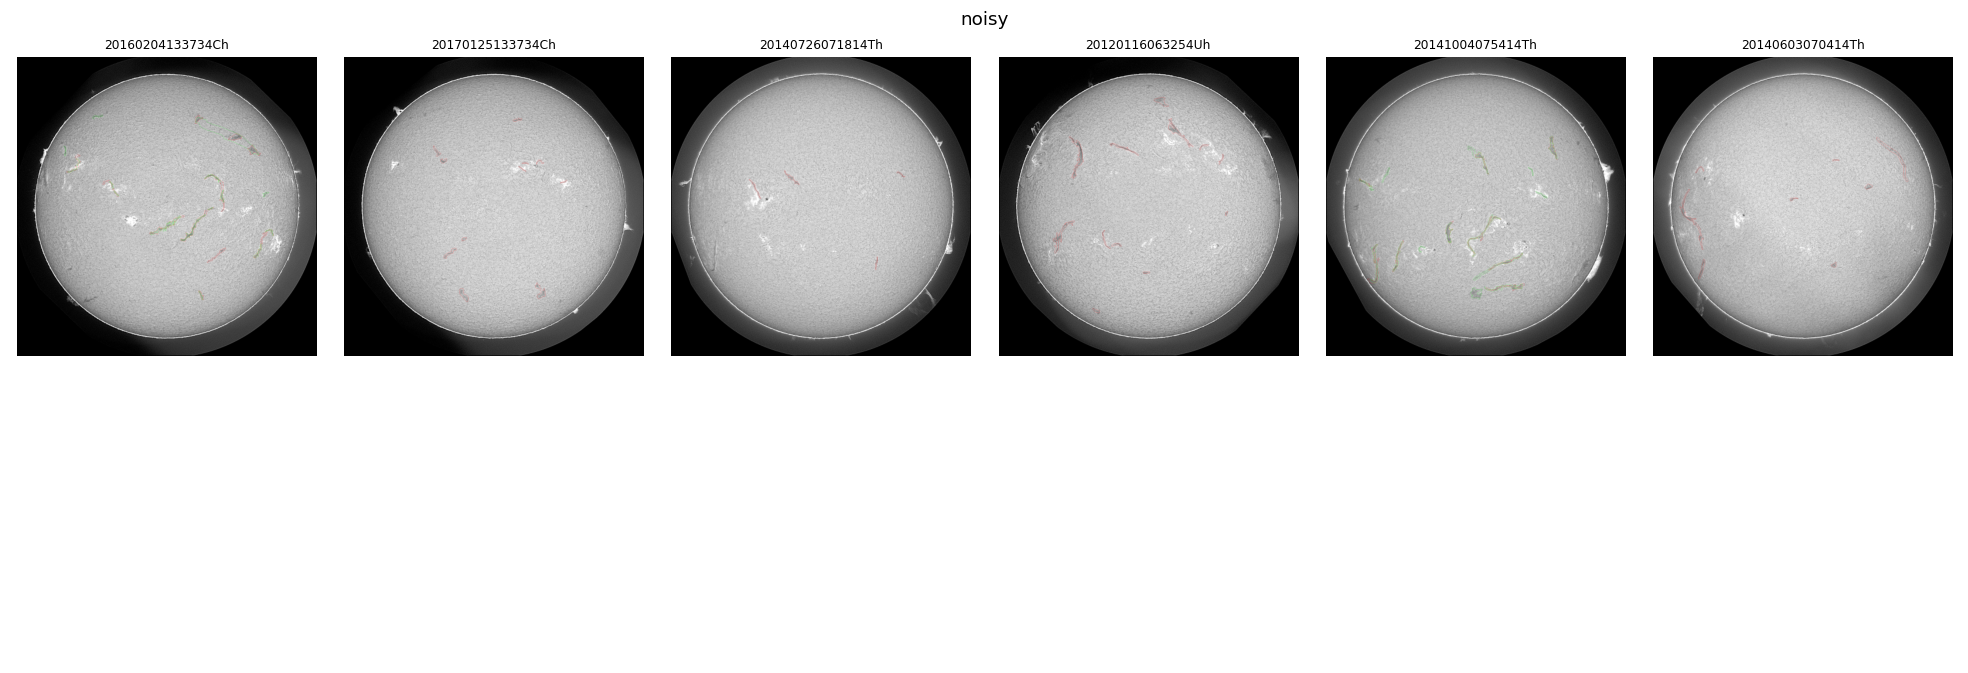

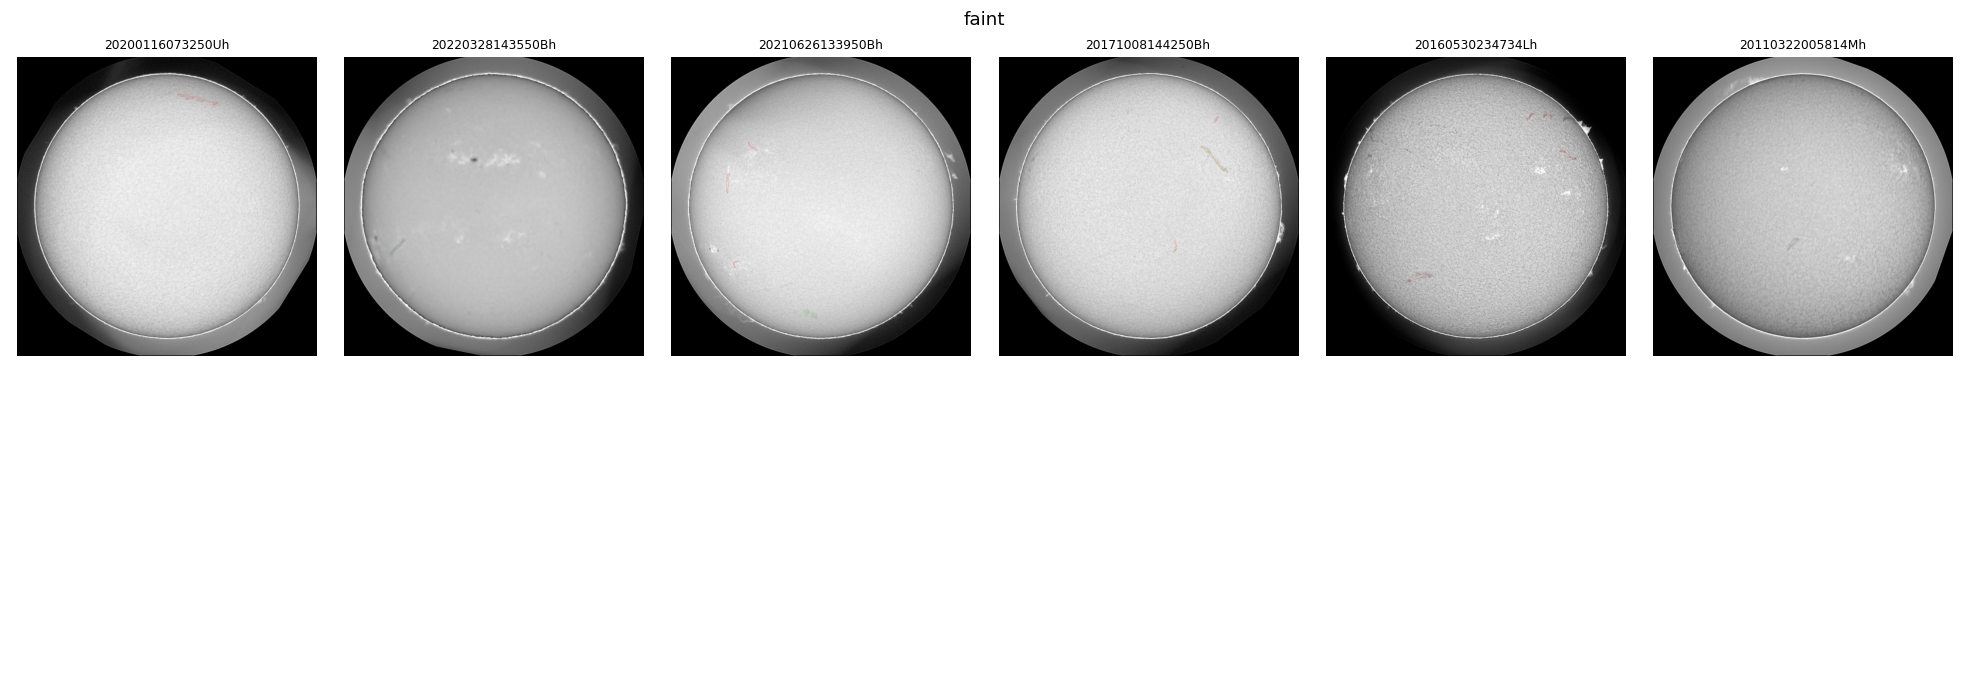

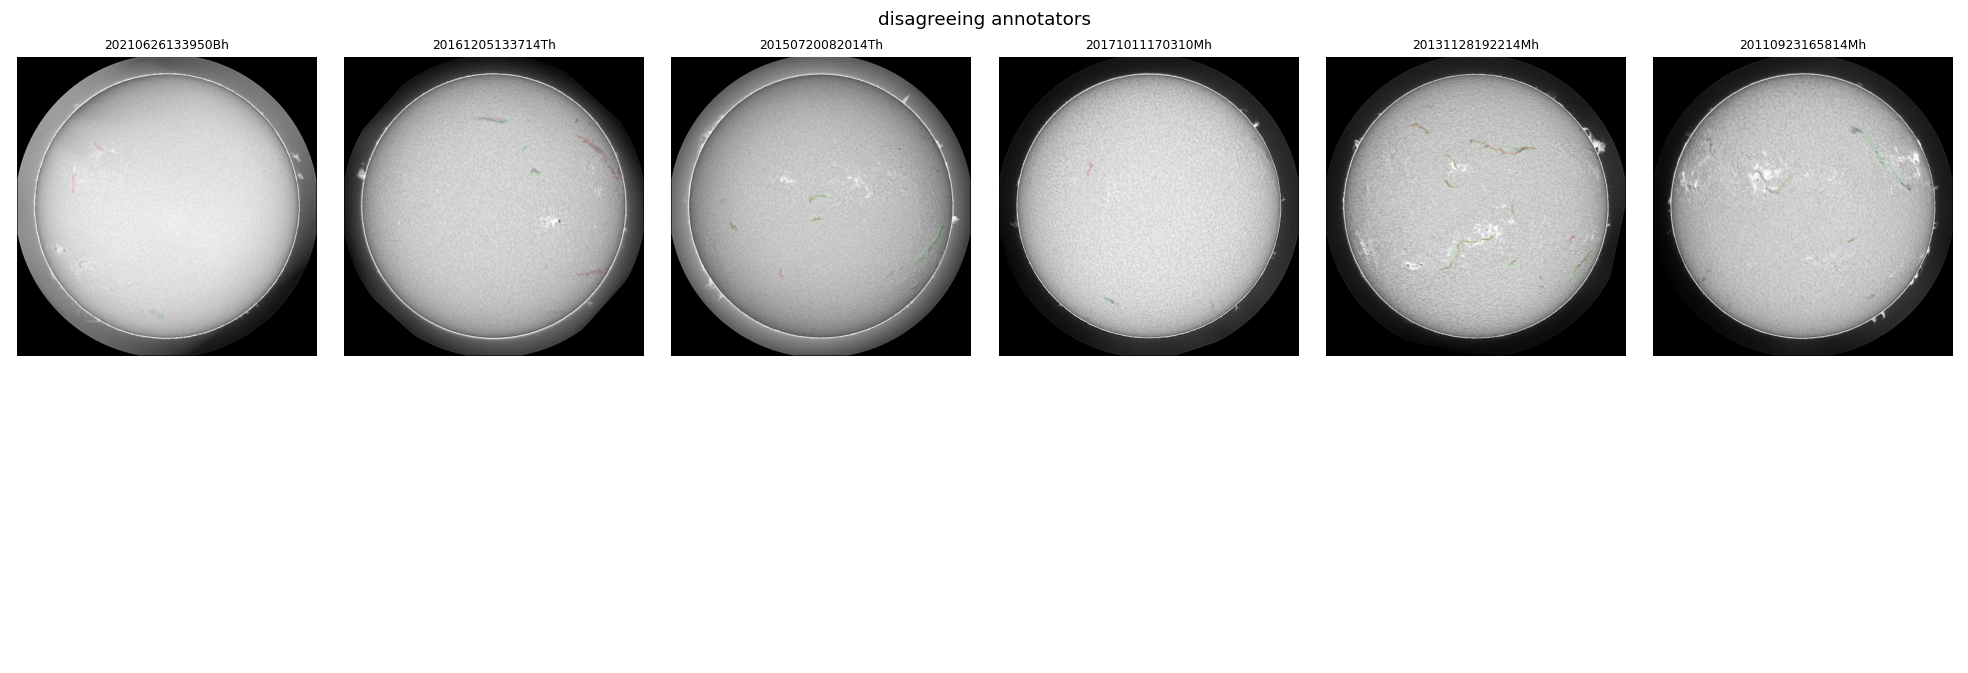

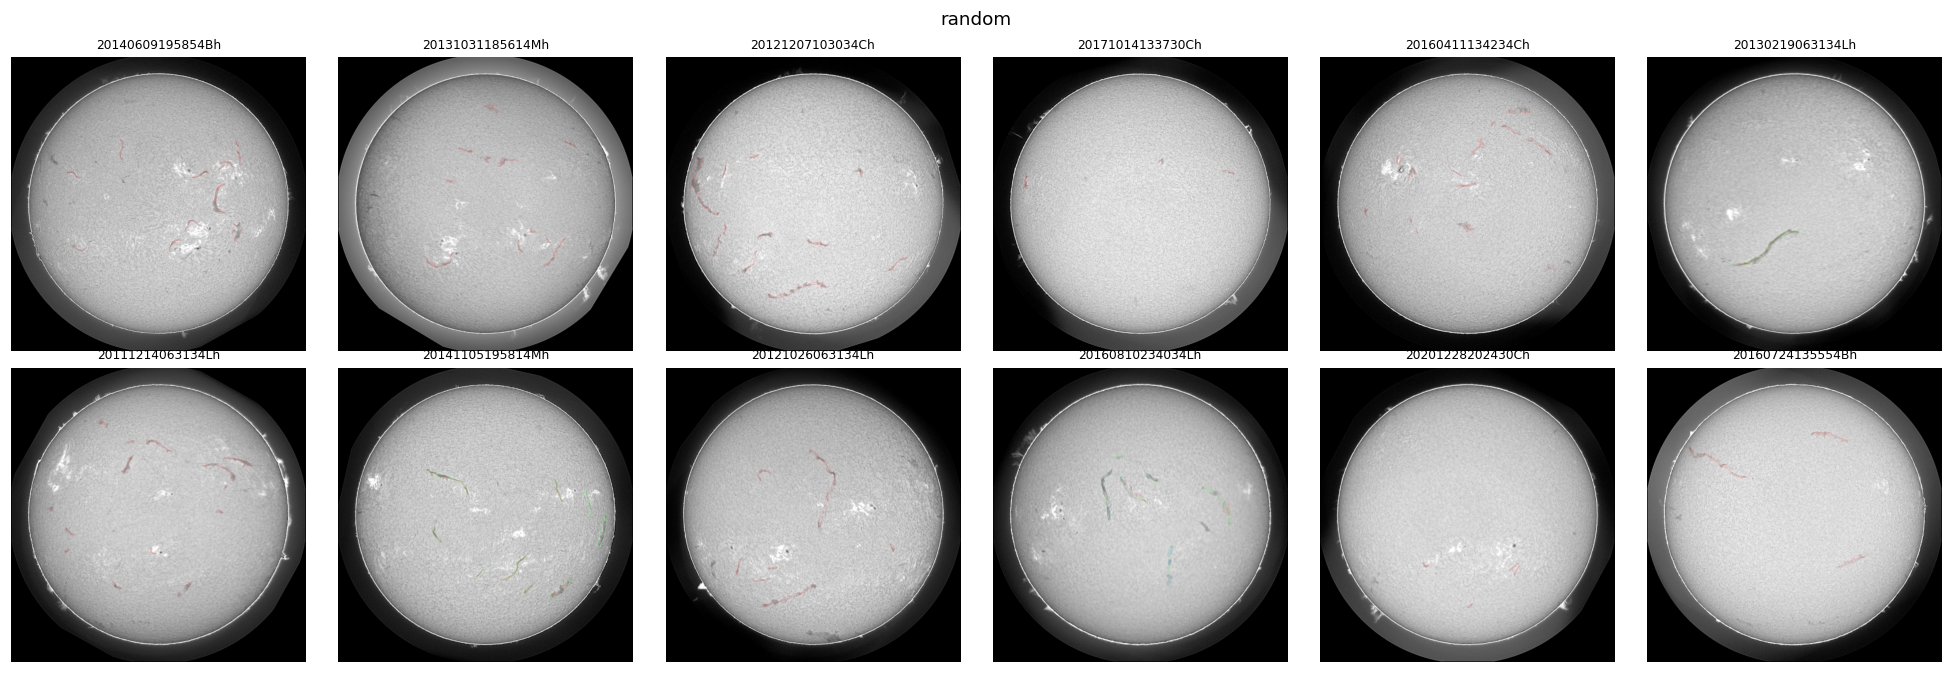

In [17]:
def noise_and_cnr(img, inst):
    disc = D.estimate_disc_mask(img)
    hf = img - cv2.GaussianBlur(img, (0, 0), 1.5)
    noise = float(hf[disc].std()) + 1e-6
    fgm = inst > 0
    if fgm.sum() < 10: return noise, np.nan
    ring = cv2.dilate(fgm.astype(np.uint8), np.ones((15, 15), np.uint8)) > 0
    bgr = ring & ~fgm & disc
    cnr = abs(float(img[fgm].mean() - img[bgr].mean())) / noise if bgr.any() else np.nan
    return noise, cnr

rng = np.random.default_rng(1)
pick = list(rng.choice(sorted(cat.obs.unique()), size=min(80, cat.obs.nunique()), replace=False))
stats = []
for o in pick:
    g = cat[cat.obs == o]
    img = D.load_image(D.TRAIN_IMG_DIR / g.file_name.iloc[0])
    inst = D.load_instance_map(g.set_id.iloc[0])
    n, c = noise_and_cnr(img, inst)
    pq = np.nan
    if len(g) > 1:
        pq = M.panoptic_quality(D.load_instance_map(g.set_id.iloc[1]), inst)["PQ"]
    stats.append(dict(obs=o, noise=n, cnr=c, agree=pq))
st = pd.DataFrame(stats)
noisy = st.nlargest(6, "noise").obs.tolist(); faint = st.dropna(subset=["cnr"]).nsmallest(6, "cnr").obs.tolist()
disagree = st.dropna(subset=["agree"]).nsmallest(6, "agree").obs.tolist()
rest = [o for o in pick if o not in noisy + faint + disagree][:12]
groups = [("noisy", noisy), ("faint", faint), ("disagreeing annotators", disagree), ("random", rest)]
SUMMARY["noisy_samples"] = {k: v for k, v in groups}

def overlay(o, size=512):
    g = cat[cat.obs == o]
    img = D.load_image(D.TRAIN_IMG_DIR / g.file_name.iloc[0])
    rgb = np.dstack([np.clip(img / max(np.percentile(img, 99.5), 1e-6), 0, 1)] * 3)
    colours = [(1, 0.2, 0.2), (0.2, 1, 0.2), (0.3, 0.5, 1)]
    for k, s in enumerate(g.set_id):
        b = find_boundaries(D.load_instance_map(s) > 0, mode="outer")
        rgb[b] = colours[k % 3]
    return cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)

for title, ids in groups:
    if not ids: continue
    fig, axs = plt.subplots(2, 6, figsize=(18, 6.2)); axs = axs.ravel()
    for a in axs: a.axis("off")
    for a, o in zip(axs, ids): a.imshow(overlay(o)); a.set_title(o, fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(f"figures/eda_samples_{title.split()[0]}.png"); plt.show()

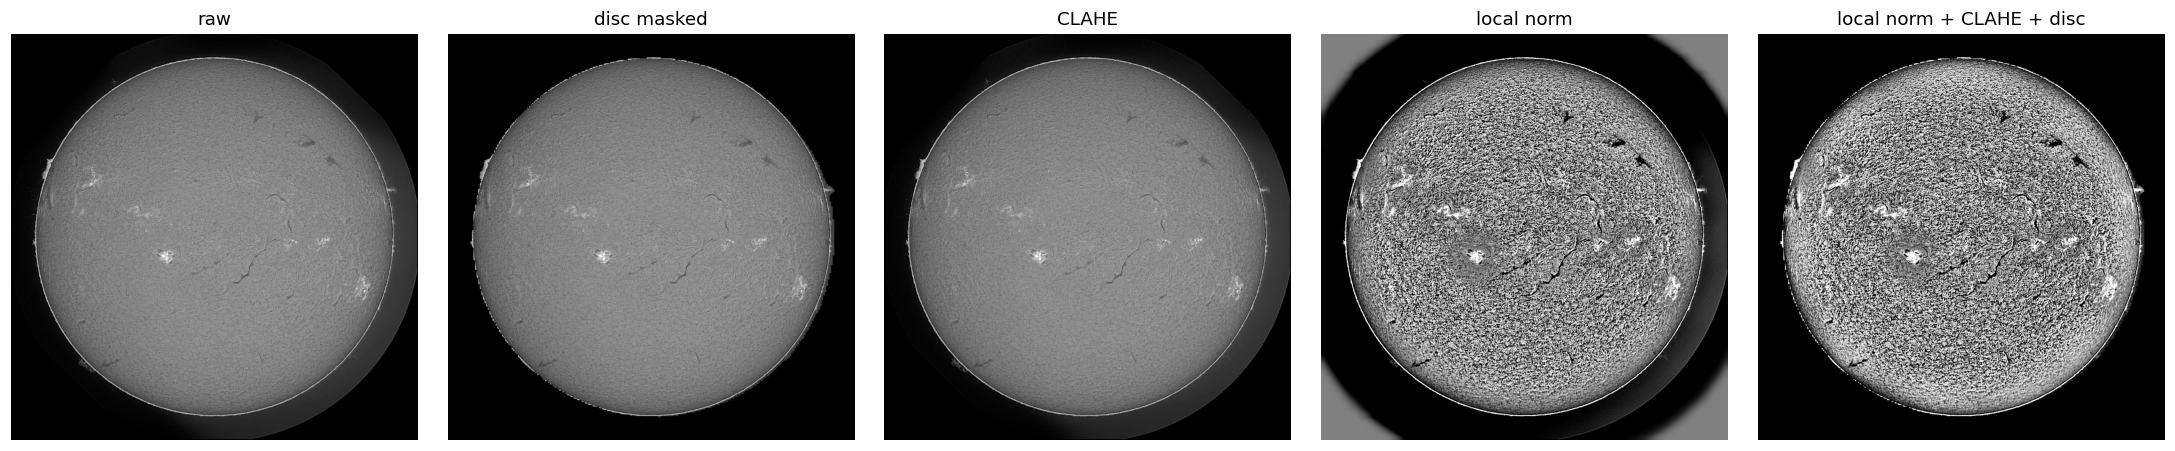

disc covers 61.6% of the frame; filament pixels outside disc (all train sets):
  mean fraction of filament pixels outside estimated disc: 0.0000


In [18]:
o = (noisy + faint)[0] if (noisy + faint) else cat.obs.iloc[0]
img = D.load_image(D.TRAIN_IMG_DIR / cat[cat.obs == o].file_name.iloc[0])
variants = {"raw": img,
            "disc masked": D.preprocess_image(img, dict(mask_disc=True)),
            "CLAHE": D.preprocess_image(img, dict(clahe=True)),
            "local norm": D.preprocess_image(img, dict(local_norm=True)),
            "local norm + CLAHE + disc": D.preprocess_image(img, dict(local_norm=True, clahe=True, mask_disc=True))}
fig, axs = plt.subplots(1, len(variants), figsize=(4 * len(variants), 4))
for a, (k, v) in zip(axs, variants.items()): a.imshow(v, cmap="gray"); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.savefig("figures/eda_preprocessing.png"); plt.show()
disc = D.estimate_disc_mask(img); print("disc covers", f"{disc.mean():.1%}", "of the frame;",
      "filament pixels outside disc (all train sets):")
out_frac = []
for s in cat.set_id.sample(min(60, len(cat)), random_state=0):
    r = cat[cat.set_id == s].iloc[0]; im = D.load_image(D.TRAIN_IMG_DIR / r.file_name); d = D.estimate_disc_mask(im)
    f = D.load_instance_map(s) > 0
    if f.any(): out_frac.append(float((f & ~d).sum() / f.sum()))
print(f"  mean fraction of filament pixels outside estimated disc: {np.mean(out_frac):.4f}" if out_frac else "  n/a")
SUMMARY["fg_outside_disc_frac"] = float(np.mean(out_frac)) if out_frac else None

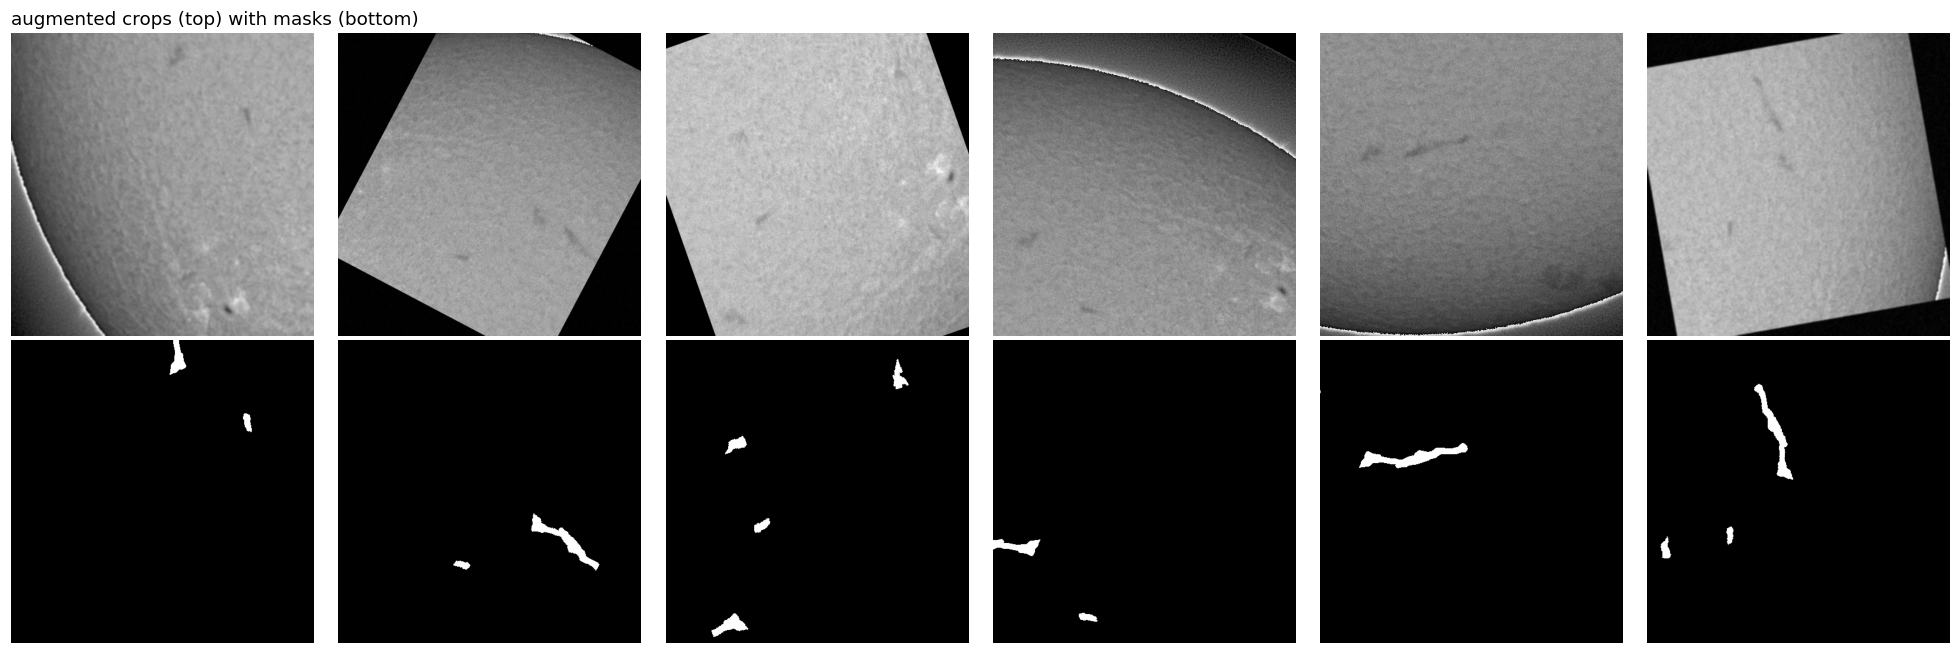

In [19]:
crop_items = D.build_items(cat, split["train"], D.TRAIN_IMG_DIR, "per_set")
pos = [it for it in crop_items if cat.loc[cat.set_id == it["set_ids"][0], "n_inst"].iloc[0] > 0][:1]
ds = D.FilamentDataset(pos, crop=512, pos_frac=1.0, augment=True)
ds0 = D.FilamentDataset(pos, crop=512, pos_frac=1.0, augment=False)
fig, axs = plt.subplots(2, 6, figsize=(18, 6))
for a in axs.ravel(): a.axis("off")
for k in range(6):
    b = ds[0]; axs[0, k].imshow(b["image"][0], cmap="gray"); axs[1, k].imshow(b["mask"][0], cmap="gray")
axs[0, 0].set_title("augmented crops (top) with masks (bottom)", loc="left")
plt.tight_layout(); plt.savefig("figures/eda_augmentation.png"); plt.show()
SUMMARY["augmentation_config"] = D.DEFAULT_AUG

In [20]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
json.dump(clean(SUMMARY), open("results/eda_summary.json", "w"), indent=1)
print(json.dumps(clean({k: v for k, v in SUMMARY.items() if k not in ("noisy_samples", "augmentation_config")}), indent=1)[:3000])

{
 "n_image_entries": 1154,
 "n_observations": 707,
 "n_annotations": 8199,
 "instruments_train": {
  "Lh": 127,
  "Ch": 125,
  "Mh": 125,
  "Bh": 118,
  "Th": 110,
  "Uh": 102
 },
 "years_train": {
  "2011": 86,
  "2012": 92,
  "2013": 101,
  "2014": 102,
  "2015": 86,
  "2016": 80,
  "2017": 71,
  "2018": 26,
  "2019": 14,
  "2020": 9,
  "2021": 28,
  "2022": 12
 },
 "date_range_train": [
  "2011-01-09 10:47:34",
  "2022-08-03 07:47:52"
 ],
 "sets_per_observation": {
  "1": 411,
  "2": 145,
  "3": 151
 },
 "filaments_per_set": {
  "count": 1154.0,
  "mean": 7.105,
  "std": 4.376,
  "min": 1.0,
  "25%": 4.0,
  "50%": 7.0,
  "75%": 10.0,
  "max": 26.0
 },
 "empty_sets": 0,
 "fg_frac_mean": 0.003589808217780792,
 "fg_frac_median": 0.0030212402343749497,
 "bg_fg_ratio": 277.5664133941386,
 "n_test_images": 180,
 "instrument_mix": {
  "train": {
   "Bh": 0.167,
   "Ch": 0.177,
   "Lh": 0.18,
   "Mh": 0.177,
   "Th": 0.156,
   "Uh": 0.144
  },
  "test": {
   "Bh": 0.183,
   "Ch": 0.183,
  